In [10]:
import warnings
warnings.filterwarnings("ignore", category=Warning)
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  

#Pull in the libraries we need
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces

#New libraries for access to model selection tasks
from sklearn.model_selection import train_test_split

In [11]:
#Pull in the plotting library and specify to display inline/static images
import matplotlib.pyplot as plt

In [12]:
#First step is to load the data into an oject
facesRaw = fetch_olivetti_faces()

In [13]:
#Notice this object has several pieces of information
facesRaw.data
facesRaw.target
print('Shape:',facesRaw.data.shape)
print(facesRaw.DESCR)

Shape: (400, 4096)
.. _olivetti_faces_dataset:

The Olivetti faces dataset
--------------------------

`This dataset contains a set of face images`_ taken between April 1992 and 
April 1994 at AT&T Laboratories Cambridge. The
:func:`sklearn.datasets.fetch_olivetti_faces` function is the data
fetching / caching function that downloads the data
archive from AT&T.

.. _This dataset contains a set of face images: https://cam-orl.co.uk/facedatabase.html

As described on the original website:

    There are ten different images of each of 40 distinct subjects. For some
    subjects, the images were taken at different times, varying the lighting,
    facial expressions (open / closed eyes, smiling / not smiling) and facial
    details (glasses / no glasses). All the images were taken against a dark
    homogeneous background with the subjects in an upright, frontal position 
    (with tolerance for some side movement).

**Data Set Characteristics:**

    =================   ==================

In [14]:
#Using the shape command, you can investigate the dimensionality
print(facesRaw.data.shape)
print(facesRaw.target.shape)

#We have 400 data samples, observations, or images each 64x64 in size
print(facesRaw.images.shape)

(400, 4096)
(400,)
(400, 64, 64)


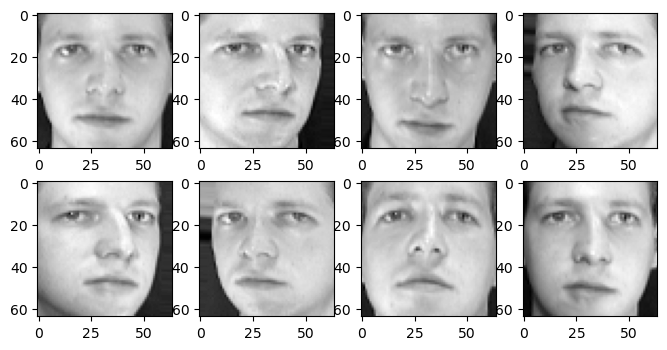

In [15]:
#Setup a figure to display the first 8 face images, in 4 columns and 2 rows
plt.figure(figsize=(4*2, 2*2))

#Loop through and plot all 8 of them in grayscale using the imshow command
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(facesRaw.images[i,:,:], cmap='gray')

In [16]:
#We can load the data into our X and y variables, and do some additional preprocessing for the CNN
X = facesRaw.images
y = facesRaw.target

In [17]:
#Split the data into training and test sets, 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [19]:
# Make results more reproducible
torch.manual_seed(42)
np.random.seed(42)

In [20]:
# Use GPU if available; otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)


Training images: (320, 64, 64)
Testing images: (80, 64, 64)


In [25]:
# ==========================================
# 3. Preprocess the data for PyTorch
# ==========================================
# Original shape:
# (number of images, height, width)
#
# CNN shape:
# (number of images, channels, height, width)

X_train = X_train[:, np.newaxis, :, :]
X_test = X_test[:, np.newaxis, :, :]
print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (320, 1, 64, 64)
Testing images: (80, 1, 64, 64)


In [26]:
# Convert NumPy arrays to PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

# Class labels must be integer tensors for CrossEntropyLoss
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("CNN input shape:", X_train.shape)
print("Training label shape:", y_train.shape)



CNN input shape: torch.Size([320, 1, 64, 64])
Training label shape: torch.Size([320])


In [27]:
# ==========================================
# 4. Create datasets and data loaders
# ==========================================
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

In [28]:
# ==========================================
# 5. Define the CNN architecture
# ==========================================
class FaceCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # First convolutional block
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Second convolutional block
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Fully connected classification layers
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 16 * 16, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 40)  # 40 people/classes

    def forward(self, x):

        # Block 1
        x = self.conv1(x)
        x = self.relu1(x)
        x = self.pool1(x)

        # Block 2
        x = self.conv2(x)
        x = self.relu2(x)
        x = self.pool2(x)

        # Classification head
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu3(x)
        x = self.fc2(x)

        # Return logits (not softmax probabilities)
        return x

In [29]:
# ==========================================
# 6. Create the model, loss, and optimizer
# ==========================================
model = FaceCNN().to(device)

loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)

FaceCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=8192, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=40, bias=True)
)


In [30]:
# ==========================================
# 7. Train the CNN
# ==========================================
num_epochs = 30

train_losses = []

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward pass: make predictions
        outputs = model(images)

        # Calculate classification loss
        loss = loss_fn(outputs, labels)

        # Clear gradients from the previous update
        optimizer.zero_grad()

        # Backpropagation: calculate gradients
        loss.backward()

        # Update model weights
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    if (epoch + 1) % 5 == 0:
        print(
            f"Epoch [{epoch + 1}/{num_epochs}], "
            f"Training Loss: {epoch_loss:.4f}"
        )



Epoch [5/30], Training Loss: 3.4465
Epoch [10/30], Training Loss: 1.1198
Epoch [15/30], Training Loss: 0.1689
Epoch [20/30], Training Loss: 0.0341
Epoch [25/30], Training Loss: 0.0118
Epoch [30/30], Training Loss: 0.0066


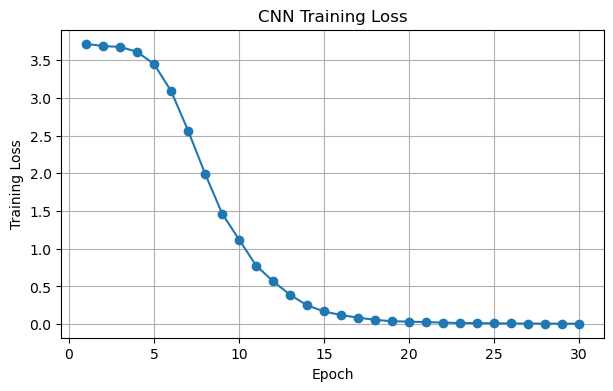

In [31]:
# ==========================================
# 9. Plot the training loss
# ==========================================
plt.figure(figsize=(7, 4))
plt.plot(range(1, num_epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("CNN Training Loss")
plt.grid(True)
plt.show()

In [32]:
# ==========================================
# 8. Evaluate the model on test data
# ==========================================
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        # Predict logits
        outputs = model(images)

        # Select the class with the largest logit
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"\nTest Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=np.arange(40),
        zero_division=0
    )
)


Test Accuracy: 0.9250
Test Accuracy: 92.50%

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       1.00      1.00      1.00         2
           2       1.00      1.00      1.00         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       0.67      1.00      0.80         2
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       1.00      0.50      0.67         2
          13       1.00      1.00      1.00         2
          14       0.67      1.00      0.80         2
          15       0.67      1.00      0.80         2
          16

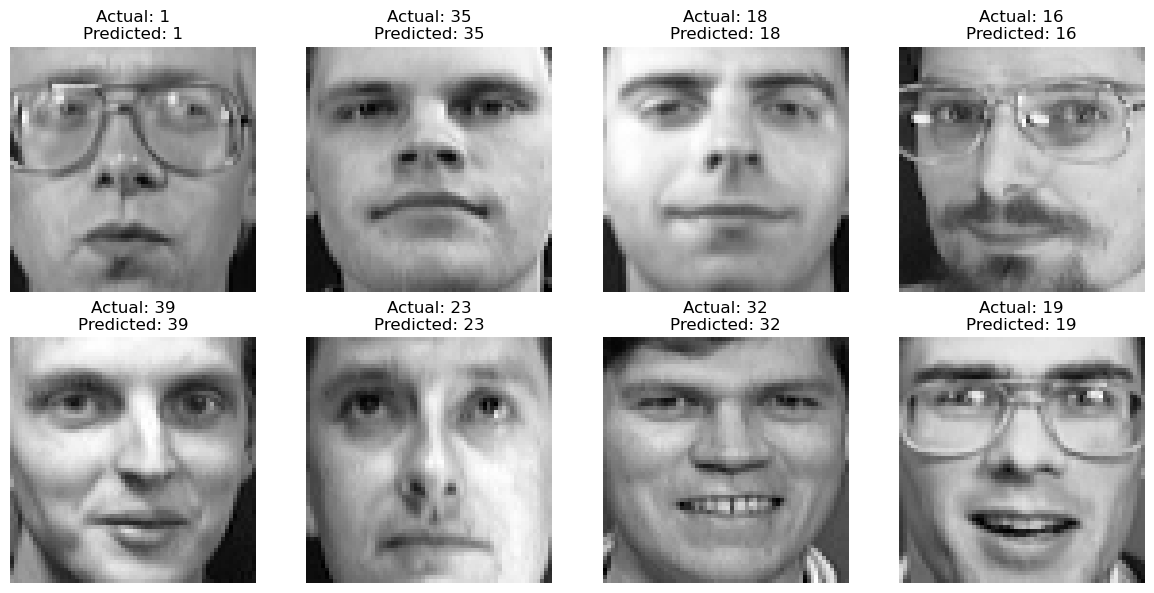

In [33]:
# ==========================================
# 10. Display sample predictions
# ==========================================
plt.figure(figsize=(12, 6))

for i in range(8):

    image = X_test[i].squeeze().numpy()
    actual = all_labels[i]
    predicted = all_predictions[i]

    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()
